<a href="https://colab.research.google.com/github/swarnapatro/AI_KickStart/blob/main/LangGraph_RAG_Ollama_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ðŸ¤– RAG Assistant with LangGraph + Local Ollama (runs from Google Colab)

**Hands-on training notebook â€“ no coding background needed.**

### What is RAG?
**R**etrieval **A**ugmented **G**eneration = *"look up the facts first, then answer."*
An LLM alone may guess or make things up. With RAG we first **search our own documents**, then give the
best matches to the LLM and say *"answer using only this"*.

### What is LangGraph?
LangGraph lets us draw our program as a **flow chart**: small steps (called *nodes*) joined by arrows (*edges*).

```
 Question â”€â”€â–º [Retrieve] â”€â”€â–º enough relevant info? â”€â”€YESâ”€â”€â–º [Generate answer] â”€â”€â–º Answer
                                      â”‚
                                      â””â”€â”€â”€â”€NOâ”€â”€â”€â”€â”€â–º [Say "I don't know"] â”€â”€â”€â”€â”€â”€â”€â–º Answer
```

### Where does everything run?
| Part | Where |
|---|---|
| This notebook (Python code) | â˜ï¸ Google Colab |
| The LLM (`llama3.2`) and embedding model (`nomic-embed-text`) | ðŸ’» **Your laptop** (Ollama) |
| Connection between them | ðŸ”— A secure tunnel (Cloudflare) that gives your laptop a temporary public web address |

### How to read this notebook
Every cell starts with a comment box: **WHAT** it does, **INPUT** it needs, **OUTPUT** you should see.
Just press â–¶ on each cell, top to bottom.

## Step 0 â€“ One-time setup on YOUR LAPTOP (before running the notebook)

Colab lives in the cloud, so it cannot see your laptop by default. We open a small "door" (tunnel).

**1. Install Ollama** from https://ollama.com and download the two models (open a terminal / command prompt):
```
ollama pull llama3.2
ollama pull nomic-embed-text
```
**2. Install cloudflared** (free, no account needed): https://developers.cloudflare.com/cloudflare-one/connections/connect-networks/downloads/
(Windows: `winget install Cloudflare.cloudflared`  |  Mac: `brew install cloudflared`)

**3. Allow Colab to talk to Ollama, then restart Ollama.**
Ollama must accept requests that come through the tunnel:
* Windows (PowerShell): `setx OLLAMA_ORIGINS "*"` â†’ then quit Ollama from the system tray and start it again.
* Mac / Linux: `OLLAMA_ORIGINS="*" ollama serve`

**4. Start the tunnel** (keep this window open during the whole session):
```
cloudflared tunnel --url http://localhost:11434 --http-host-header="localhost:11434"
```
After a few seconds it prints an address like `https://random-words-1234.trycloudflare.com`.
**Copy that address** â€“ you will paste it in Step 2 below.

> âš ï¸ Security note: anyone who knows that address can use your Ollama while the tunnel is open.
> Close the tunnel window (Ctrl+C) when the session ends. The address changes every time.

## Step 1 â€“ Install the libraries

In [ ]:
# =====================================================================
# CELL: Install libraries
# WHAT : Downloads the Python packages this notebook needs (only once per Colab session).
# INPUT : none
# OUTPUT: Some installation messages (the -q flag keeps them short). No error = success.
# =====================================================================

# "%pip install" = install Python packages. Packages used:
#   langgraph               -> builds our flow chart (graph) of steps
#   langchain-ollama        -> lets Python talk to the Ollama LLM / embedding models
#   langchain-core          -> basic building blocks (documents, vector store, prompts)
#   langchain-text-splitters-> cuts long text into small pieces ("chunks")
#   numpy                   -> math library used by the vector store to compare meanings
#   requests               -> simple tool to check that the laptop connection works
%pip install -q langgraph langchain-ollama langchain-core langchain-text-splitters numpy requests

## Step 2 â€“ Connect to the Ollama running on your laptop
Paste the tunnel address from Step 0 into the cell below.

In [ ]:
# =====================================================================
# CELL: Settings (the only cell you need to edit!)
# WHAT : Stores the address of your laptop's Ollama and the names of the two models.
# INPUT : OLLAMA_URL -> the https://....trycloudflare.com address printed by cloudflared on your laptop
#         (If you run this notebook directly ON your laptop, keep http://localhost:11434)
# OUTPUT: Prints the settings so you can double-check them.
# =====================================================================

# Address of Ollama. Replace the text between the quotes with YOUR tunnel address (no slash at the end).
#OLLAMA_URL = "http://localhost:11434"          # e.g. "https://random-words-1234.trycloudflare.com" the below need to replace
OLLAMA_URL = "https://refined-ratio-permanent-proof.trycloudflare.com"
LLM_MODEL = "llama3.2"                          # the "brain" that writes the answer
EMBED_MODEL = "nomic-embed-text"                # the model that turns text into numbers so we can search by meaning

# How many matching text chunks to fetch for each question
TOP_K = 3
# Minimum "similarity" (0 to 1) a chunk needs to count as relevant. Higher = stricter.
MIN_SCORE = 0.6

print("Ollama address :", OLLAMA_URL)
print("LLM model      :", LLM_MODEL)
print("Embedding model:", EMBED_MODEL)

Ollama address : https://refined-ratio-permanent-proof.trycloudflare.com
LLM model      : llama3.2
Embedding model: nomic-embed-text


In [ ]:
# =====================================================================
# CELL: Connection test
# WHAT : Asks your laptop's Ollama "which models do you have?" to prove the connection works.
# INPUT : OLLAMA_URL, LLM_MODEL and EMBED_MODEL from the previous cell.
# OUTPUT: "Connected!" and a list of models. If something is wrong you get a friendly hint instead.
# =====================================================================

import requests   # a small library to visit web addresses from Python

try:
    # Visit <OLLAMA_URL>/api/tags - Ollama replies with a list of installed models (in JSON format).
    # The extra header avoids a warning page if you use ngrok instead of cloudflared.
    reply = requests.get(OLLAMA_URL + "/api/tags",
                         headers={"ngrok-skip-browser-warning": "1"}, timeout=20)
    reply.raise_for_status()                                   # stop with an error if the reply was not OK
    installed = [m["name"] for m in reply.json()["models"]]    # pick just the model names
    print("âœ… Connected! Models found on your laptop:", installed)

    # Check that the two models we need are really installed
    for needed in (LLM_MODEL, EMBED_MODEL):
        if not any(name.startswith(needed) for name in installed):
            print(f"âš ï¸ Model '{needed}' is missing. On your laptop run:  ollama pull {needed}")
except Exception as error:
    print("âŒ Could not reach Ollama.")
    print("   Checklist: 1) Ollama is running  2) cloudflared window is open  3) OLLAMA_URL is pasted correctly")
    print("   Technical detail:", error)

âœ… Connected! Models found on your laptop: ['llama3.1:8b', 'nomic-embed-text:latest', 'qwen3:4b', 'llama3.2:latest']


## Step 3 â€“ Import the tools we will use

In [ ]:
# =====================================================================
# CELL: Imports
# WHAT : Loads the ready-made tools (classes/functions) we need. Think of it as taking tools out of a toolbox.
# INPUT : none
# OUTPUT: nothing printed (silence = success).
# =====================================================================

# TypedDict : lets us describe the "shape" of the data that travels through our graph (the State).
from typing import TypedDict, List

# ChatOllama     : the LLM (chat brain) running on your laptop via Ollama.
# OllamaEmbeddings: converts text -> list of numbers ("embedding") so the computer can compare MEANING.
from langchain_ollama import ChatOllama, OllamaEmbeddings

# Document : a small container holding a piece of text (+ optional label such as its source).
from langchain_core.documents import Document

# InMemoryVectorStore : a simple "search engine by meaning" that lives in memory (no database to install).
from langchain_core.vectorstores import InMemoryVectorStore

# ChatPromptTemplate : a fill-in-the-blanks instruction we send to the LLM.
from langchain_core.prompts import ChatPromptTemplate

# RecursiveCharacterTextSplitter : cuts long text into small chunks at natural places (paragraphs, sentences).
from langchain_text_splitters import RecursiveCharacterTextSplitter

# StateGraph : the flow-chart builder of LangGraph.  START / END : the begin and finish points of the flow chart.
from langgraph.graph import StateGraph, START, END

print("Imports done âœ…")

Imports done âœ…


## Step 4 â€“ Create the two Ollama models (LLM + embeddings)

In [ ]:
# =====================================================================
# CELL: Create the LLM and the embedding model
# WHAT : Prepares two "connections" to models running on your laptop.
# INPUT : OLLAMA_URL, LLM_MODEL, EMBED_MODEL
# OUTPUT: A short test sentence from the LLM and the size of one embedding.
# =====================================================================

# Extra web header: harmless for cloudflared, avoids a warning page when people use ngrok.
extra_headers = {"client_kwargs": {"headers": {"ngrok-skip-browser-warning": "1"}}}

# The LLM. temperature=0 means "be factual and consistent, don't be creative" - ideal for RAG.
llm = ChatOllama(model=LLM_MODEL, base_url=OLLAMA_URL, temperature=0, **extra_headers)

# The embedding model. It turns any text into a list of numbers that represent its meaning.
embeddings = OllamaEmbeddings(model=EMBED_MODEL, base_url=OLLAMA_URL, **extra_headers)

# --- Quick test 1: ask the LLM a simple question (INPUT: text -> OUTPUT: text) ---
print("LLM says       :", llm.invoke("Say hello to the students in one short sentence.").content)

# --- Quick test 2: embed one word (INPUT: text -> OUTPUT: list of numbers) ---
vector = embeddings.embed_query("hello")
print("Embedding size :", len(vector), "numbers  (first 3:", [round(x, 3) for x in vector[:3]], ")")

LLM says       : Hello to all the students!
Embedding size : 768 numbers  (first 3: [0.018, -0.006, -0.175] )


## Step 5 â€“ Our knowledge base (the documents the assistant may use)
We invent a small fictional company, **Sunrise Training Academy**. The LLM has never seen this text â€“
so it can only answer correctly if RAG works!

ðŸ’¡ *Want to try your own content? Replace the text below with your own notes, policies or FAQs.*

In [ ]:
# =====================================================================
# CELL: Knowledge base text
# WHAT : Holds the raw text our assistant will "read". In real projects this comes from PDFs, web pages or databases.
# INPUT : none (you can edit the text!)
# OUTPUT: Prints how many characters the text contains.
# =====================================================================

knowledge_text = """
Sunrise Training Academy was founded in 2015 and is headquartered in Pune, India.
The academy offers courses in Data Science, Cloud Computing and Generative AI.

Course fees: The Data Science course costs 60,000 rupees. The Generative AI course costs 45,000 rupees.
The Cloud Computing course costs 50,000 rupees. Students who enrol in two courses together get a 10 percent discount.

Class timings: Weekday batches run from 7 PM to 9 PM, Monday to Friday. Weekend batches run on Saturday
and Sunday from 10 AM to 1 PM. All classes are recorded and the recordings stay available for 6 months.

Refund policy: A student can request a full refund within 7 days of the first class. After 7 days no refund
is given, but the student may transfer the seat to another batch once, free of charge.

Certification: Students receive a completion certificate when they attend at least 80 percent of the classes
and submit the final project. The certificate is signed by the academy director, Dr. Meera Nair.

Placement support: The academy runs a placement cell that organises mock interviews and resume workshops.
In 2025, 320 students were placed with an average salary of 7.2 lakh rupees per year.

Contact: Email support@sunriseacademy.example or call +91-20-5550-1234 between 9 AM and 6 PM, Monday to Saturday.
The academy is closed on public holidays.
"""

print("Knowledge text loaded:", len(knowledge_text), "characters")

Knowledge text loaded: 1347 characters


## Step 6 â€“ Chunking & indexing (the "Retrieval" preparation)
1. **Chunk** â€“ cut the text into small pieces (an LLM and a search work better on short passages).
2. **Embed** â€“ convert every chunk into numbers that capture its meaning.
3. **Store** â€“ save them in a vector store, which can later find "the chunks closest in meaning to a question".

In [ ]:
# =====================================================================
# CELL: Split text into chunks
# WHAT : Cuts the long text into small overlapping pieces.
# INPUT : knowledge_text (one long string)
# OUTPUT: A list of chunks (Documents). We print how many and show the first one.
# =====================================================================

splitter = RecursiveCharacterTextSplitter(
    chunk_size=350,      # maximum characters in one chunk
    chunk_overlap=50,    # repeat 50 characters between neighbours so a sentence is not cut in a bad place
)

# Wrap the text in a Document, then split. "source" is a label we can show later as a citation.
chunks = splitter.split_documents([Document(page_content=knowledge_text, metadata={"source": "Academy FAQ"})])

print("Number of chunks:", len(chunks))
print("--- Chunk #1 ---")
print(chunks[0].page_content)

Number of chunks: 7
--- Chunk #1 ---
Sunrise Training Academy was founded in 2015 and is headquartered in Pune, India.
The academy offers courses in Data Science, Cloud Computing and Generative AI.


In [ ]:
# =====================================================================
# CELL: Build the vector store (our "search by meaning" engine)
# WHAT : Embeds every chunk (via Ollama on your laptop) and stores the numbers.
# INPUT : chunks (list of Documents), embeddings (embedding model)
# OUTPUT: A search test: the 2 chunks closest in meaning to "How much is the AI course?" with their scores.
# =====================================================================

vector_store = InMemoryVectorStore(embedding=embeddings)   # an empty "search engine"
vector_store.add_documents(chunks)                          # embed + store all chunks (takes a few seconds)
print("Stored", len(chunks), "chunks in the vector store âœ…")

# --- Quick test of retrieval alone (no LLM involved yet) ---
# similarity_search_with_score returns pairs of (chunk, score). Score near 1 = very similar in meaning.
test = vector_store.similarity_search_with_score("How much is the AI course?", k=2)
for doc, score in test:
    print(f"\nscore={score:.2f} | {doc.page_content[:120]}...")

Stored 7 chunks in the vector store âœ…

score=0.76 | Course fees: The Data Science course costs 60,000 rupees. The Generative AI course costs 45,000 rupees.
The Cloud Comput...

score=0.56 | Certification: Students receive a completion certificate when they attend at least 80 percent of the classes
and submit ...


## Step 7 â€“ Build the LangGraph flow chart
We need three things:
1. **State** â€“ a shared "notebook page" that every step can read and write.
2. **Nodes** â€“ the steps (plain Python functions).
3. **Edges** â€“ the arrows connecting the steps (one is a *conditional* arrow = a decision).

In [ ]:
# =====================================================================
# CELL: Define the State
# WHAT : Describes what information travels through the graph - like columns on a form.
# INPUT : none
# OUTPUT: nothing printed.
# =====================================================================

class RAGState(TypedDict):
    question: str            # what the user asked                      (filled at the start)
    context: List[Document]  # relevant chunks found by the search      (filled by the Retrieve step)
    answer: str              # the final reply                          (filled by Generate / No-answer step)

In [ ]:
# =====================================================================
# CELL: Node 1 - Retrieve
# WHAT : Searches the vector store for chunks that match the question and keeps only the good ones.
# INPUT : state["question"]               e.g. "What is the refund policy?"
# OUTPUT: {"context": [chunk, chunk, ...]} - an empty list means nothing relevant was found.
# =====================================================================

def retrieve(state: RAGState) -> dict:
    question = state["question"]

    # Find the TOP_K chunks whose meaning is closest to the question, each with a similarity score.
    results = vector_store.similarity_search_with_score(question, k=TOP_K)

    # Keep only chunks whose score is at least MIN_SCORE (filters out unrelated text).
    good_chunks = [doc for doc, score in results if score >= MIN_SCORE]

    print(f"   [Retrieve] scores: {[round(s, 2) for _, s in results]} -> kept {len(good_chunks)} chunk(s)")
    return {"context": good_chunks}      # a node returns ONLY the parts of the State it wants to update

In [ ]:
# =====================================================================
# CELL: Node 2 - Generate (the "G" in RAG)
# WHAT : Gives the retrieved chunks + the question to the LLM and asks for an answer based ONLY on those chunks.
# INPUT : state["question"], state["context"]
# OUTPUT: {"answer": "<text written by the LLM>"}
# =====================================================================

# The instruction ("prompt") sent to the LLM. {context} and {question} are blanks filled in at run time.
prompt = ChatPromptTemplate.from_template(
    """You are a helpful assistant for Sunrise Training Academy.
Answer the question using ONLY the context below. Keep the answer short and clear.
If the context does not contain the answer, say you do not know.

Context:
{context}

Question: {question}

Answer:"""
)

def generate(state: RAGState) -> dict:
    # Join all retrieved chunks into one block of text, separated by blank lines.
    context_text = "\n\n".join(doc.page_content for doc in state["context"])

    # Fill the blanks in the prompt, then send it to the LLM running on your laptop.
    messages = prompt.invoke({"context": context_text, "question": state["question"]})
    reply = llm.invoke(messages)

    print("   [Generate] LLM wrote the answer from", len(state["context"]), "chunk(s)")
    return {"answer": reply.content}

In [ ]:
# =====================================================================
# CELL: Node 3 - No answer (safety net) + the decision function
# WHAT : If nothing relevant was found we politely say so instead of letting the LLM guess (prevents "hallucination").
#        "decide_next_step" is the decision-maker for the conditional arrow.
# INPUT : state["context"]
# OUTPUT: no_answer -> {"answer": "..."}      decide_next_step -> the name of the next node ("generate" or "no_answer")
# =====================================================================

def no_answer(state: RAGState) -> dict:
    print("   [No answer] nothing relevant found in the documents")
    return {"answer": "Sorry, I could not find this in the Sunrise Academy documents, so I would rather not guess."}

def decide_next_step(state: RAGState) -> str:
    # If the Retrieve step found at least one good chunk -> go and generate the answer, otherwise -> give up politely.
    return "generate" if len(state["context"]) > 0 else "no_answer"

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	retrieve(retrieve)
	generate(generate)
	no_answer(no_answer)
	__end__([<p>__end__</p>]):::last
	__start__ --> retrieve;
	retrieve -.-> generate;
	retrieve -.-> no_answer;
	generate --> __end__;
	no_answer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



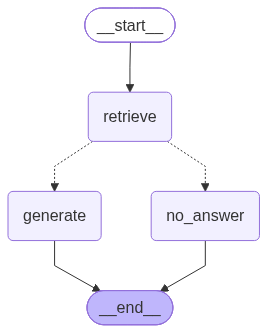

In [ ]:
# =====================================================================
# CELL: Assemble and compile the graph
# WHAT : Adds the steps (nodes) to the flow chart and connects them with arrows (edges).
# INPUT : the three node functions defined above
# OUTPUT: A text drawing of the flow chart (Mermaid format) and, if available, a picture.
# =====================================================================

builder = StateGraph(RAGState)                 # start an empty flow chart that uses our State

# 1) Add the steps ("name", function)
builder.add_node("retrieve", retrieve)
builder.add_node("generate", generate)
builder.add_node("no_answer", no_answer)

# 2) Draw the arrows
builder.add_edge(START, "retrieve")            # begin -> Retrieve
builder.add_conditional_edges(                 # Retrieve -> (decision) -> Generate OR No-answer
    "retrieve",
    decide_next_step,
    {"generate": "generate", "no_answer": "no_answer"},
)
builder.add_edge("generate", END)              # Generate -> finish
builder.add_edge("no_answer", END)             # No-answer -> finish

# 3) compile() checks the chart is valid and turns it into a runnable app
rag_app = builder.compile()

# Show the flow chart. The text version always works; the picture needs internet access (works in Colab).
print(rag_app.get_graph().draw_mermaid())
try:
    from IPython.display import Image, display
    display(Image(rag_app.get_graph().draw_mermaid_png()))
except Exception:
    print("(Picture not available here - the text above is the same chart.)")

## Step 8 â€“ Ask questions! ðŸŽ‰
`rag_app.invoke(...)` runs the whole flow chart: **question in â†’ answer out**.

In [ ]:
# =====================================================================
# CELL: Helper function "ask"
# WHAT : A friendly wrapper: sends a question through the graph and prints the answer + the sources used.
# INPUT : question (text)
# OUTPUT: Printed answer. Also returns the final State so you can inspect it.
# =====================================================================

def ask(question: str):
    print("\nâ“ Question:", question)
    # invoke() starts the graph. We give the initial State: only "question" is known at the start.
    final_state = rag_app.invoke({"question": question, "context": [], "answer": ""})
    print("ðŸ’¬ Answer  :", final_state["answer"])
    if final_state["context"]:
        print("ðŸ“š Sources :", {d.metadata["source"] for d in final_state["context"]})
    return final_state

In [ ]:
# =====================================================================
# CELL: Try questions that ARE in our documents
# WHAT : Runs the full RAG flow for three questions.
# INPUT : three question strings
# OUTPUT: For each: retrieval scores, then the LLM answer built from our documents, e.g.
#         Q "How much does the Generative AI course cost?" -> "The Generative AI course costs 45,000 rupees."
# =====================================================================

ask("How much does the Generative AI course cost?")
ask("Can I get my money back if I do not like the course?")
ask("What do I need to do to receive the certificate, and who signs it?")


â“ Question: How much does the Generative AI course cost?
   [Retrieve] scores: [0.81, 0.55, 0.54] -> kept 1 chunk(s)
   [Generate] LLM wrote the answer from 1 chunk(s)
ðŸ’¬ Answer  : The Generative AI course costs 45,000 rupees.
ðŸ“š Sources : {'Academy FAQ'}

â“ Question: Can I get my money back if I do not like the course?
   [Retrieve] scores: [0.67, 0.54, 0.5] -> kept 1 chunk(s)
   [Generate] LLM wrote the answer from 1 chunk(s)
ðŸ’¬ Answer  : No, you can only get a full refund within 7 days of the first class.
ðŸ“š Sources : {'Academy FAQ'}

â“ Question: What do I need to do to receive the certificate, and who signs it?
   [Retrieve] scores: [0.69, 0.49, 0.46] -> kept 1 chunk(s)
   [Generate] LLM wrote the answer from 1 chunk(s)
ðŸ’¬ Answer  : To receive the certificate, you need to attend at least 80 percent of the classes and submit the final project. The certificate is signed by Dr. Meera Nair, the academy director.
ðŸ“š Sources : {'Academy FAQ'}


{'question': 'What do I need to do to receive the certificate, and who signs it?',
 'context': [Document(id='ccc64179-4ee0-4e80-b7ef-95211f1d6117', metadata={'source': 'Academy FAQ'}, page_content='Certification: Students receive a completion certificate when they attend at least 80 percent of the classes\nand submit the final project. The certificate is signed by the academy director, Dr. Meera Nair.')],
 'answer': 'To receive the certificate, you need to attend at least 80 percent of the classes and submit the final project. The certificate is signed by Dr. Meera Nair, the academy director.'}

In [ ]:
# =====================================================================
# CELL: Try a question that is NOT in our documents
# WHAT : Shows the safety net: the graph takes the other branch (No answer) instead of guessing.
# INPUT : an unrelated question
# OUTPUT: Low retrieval scores, then the polite "could not find this" message.
# =====================================================================

ask("Who won the cricket world cup in 2011?")


â“ Question: Who won the cricket world cup in 2011?
   [Retrieve] scores: [0.47, 0.44, 0.44] -> kept 0 chunk(s)
   [No answer] nothing relevant found in the documents
ðŸ’¬ Answer  : Sorry, I could not find this in the Sunrise Academy documents, so I would rather not guess.


{'question': 'Who won the cricket world cup in 2011?',
 'context': [],
 'answer': 'Sorry, I could not find this in the Sunrise Academy documents, so I would rather not guess.'}

## Step 9 â€“ (Optional) Chat with your assistant
Set `RUN_CHAT = True` and run the cell. Type a question and press Enter; type `quit` to stop.

In [ ]:
# =====================================================================
# CELL: Interactive chat (optional)
# WHAT : A simple loop where you type questions and the assistant answers.
# INPUT : whatever you type in the box that appears. Type "quit" to stop.
# OUTPUT: The answer for each question.
# =====================================================================

RUN_CHAT = False        # change to True to start chatting

while RUN_CHAT:
    user_question = input("Your question (or 'quit'): ").strip()
    if user_question.lower() in ("quit", "exit", ""):
        print("Bye! ðŸ‘‹")
        break
    ask(user_question)

## ðŸ§ª Ideas to try (exercises)
1. **Change `MIN_SCORE`** (Step 2) to `0.3` and ask the cricket question again â€“ what happens? Then try `0.8`.
2. **Edit the knowledge text** (Step 5): change a fee, re-run Steps 6 â†’ 8, and see the answer change.
3. **Change `TOP_K`** to `1` or `5` â€“ does the answer quality change?
4. **Swap the model**: set `LLM_MODEL = "llama3.1:8b"` (needs `ollama pull llama3.1:8b`) and compare.
5. **Add a new node** (e.g., one that translates the answer to Hindi) and connect it before `END`.

## âœ… Recap
* **Retrieve** finds relevant text â†’ **Generate** writes the answer from it â†’ a **decision** avoids guessing.
* LangGraph = nodes + edges + shared State. RAG = search first, then answer.
* The "brain" ran on **your laptop**, while the code ran in **Colab**.

**After the session:** stop the `cloudflared` window (Ctrl+C) to close the tunnel.